# T-21 區域型事件候選：國家測站 60 天

**目的：**T-20 的單日微型感測器資料沒有遇到區域型事件，Algorithm 2 的區域型規則無從驗證。
這裡先用環境部國家測站 60 天的小時資料，找出「多站同時升高」的日子與時段，作為之後驗證的候選事件。

**方法：**`src/analytics/regional.py`。
- 升高：測站 PM2.5 比自己之前的中位數（日尺度：前 14 天；時尺度：前 7 天）高 50% 以上，**且**至少高 5 μg/m³
- 一致性 C：同時升高的測站比例；區域型候選要求 C ≥ 0.8、測站間變異係數 CV ≤ 0.25
- 局部型候選：單一測站比其他測站中位數高 max(10, 50%) 以上，且 C < 0.3

**只描述空間型態，不判斷成因。**

In [1]:
import os, sys, glob, warnings
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT); sys.path.insert(0, str(ROOT)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from zoneinfo import ZoneInfo
from src.analytics import regional as rg
TZ = ZoneInfo("Asia/Taipei")  # matplotlib 預設用 UTC 標時間軸

plt.rcParams.update({"font.sans-serif": ["Microsoft JhengHei", "Noto Sans CJK TC", "sans-serif"],
                     "axes.unicode_minus": False, "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
                     "grid.linewidth": 0.6, "axes.edgecolor": "#52514e", "text.color": "#0b0b0b",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
BLUE, ORANGE, INK2, GRID = "#2a78d6", "#eb6834", "#52514e", "#e6e5e1"
FIG = ROOT / "notebooks" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
CITIES = ["臺中市", "高雄市"]

def load(city):
    df = pd.concat([pd.read_csv(f, dtype={"siteid": str}) for f in glob.glob(str(ROOT / "data/raw/moenv" / city / "*.csv.gz"))])
    df["time"] = pd.to_datetime(df["time"]).dt.tz_convert("Asia/Taipei")
    return df.drop_duplicates(["siteid", "time"])

raw = {c: load(c) for c in CITIES}
names = {c: raw[c].drop_duplicates("siteid").set_index("siteid")["sitename"] for c in CITIES}
H = {c: rg.hourly_matrix(raw[c]) for c in CITIES}
D = {c: rg.daily_candidates(H[c]) for c in CITIES}
P = {c: rg.hourly_profile(H[c]) for c in CITIES}
for c in CITIES:
    print(f"{c}: {H[c].shape[1]} 站，{H[c].index.min():%Y-%m-%d} ～ {H[c].index.max():%Y-%m-%d}")

臺中市: 6 站，2026-08-20 ～ 2026-10-19
高雄市: 12 站，2026-08-20 ～ 2026-10-19


## 1. 區域型候選日

In [2]:
for c in CITIES:
    d = D[c]
    print(f"\n{c}：{int(d['regional_candidate'].sum())} 個候選日")
    print(d[d["regional_candidate"]].round(2).to_string())


臺中市：7 個候選日
                            mean    min    max  n_sites     C    CV  ratio_to_base  regional_candidate
2026-09-08 00:00:00+08:00  13.82  12.17  15.92        5  1.00  0.11           1.98                True
2026-09-09 00:00:00+08:00  13.64  10.96  16.73        6  0.83  0.15           1.78                True
2026-09-13 00:00:00+08:00  16.44  14.68  17.59        6  1.00  0.07           1.89                True
2026-10-12 00:00:00+08:00  20.45  16.91  22.39        6  0.83  0.10           1.67                True
2026-10-13 00:00:00+08:00  28.54  22.86  30.86        6  1.00  0.11           2.16                True
2026-10-14 00:00:00+08:00  24.14  21.26  26.65        6  1.00  0.09           1.82                True
2026-10-17 00:00:00+08:00  26.51  24.71  28.91        6  1.00  0.06           1.70                True

高雄市：4 個候選日
                            mean    min    max  n_sites     C    CV  ratio_to_base  regional_candidate
2026-09-09 00:00:00+08:00  14.77  11.59  17.27   

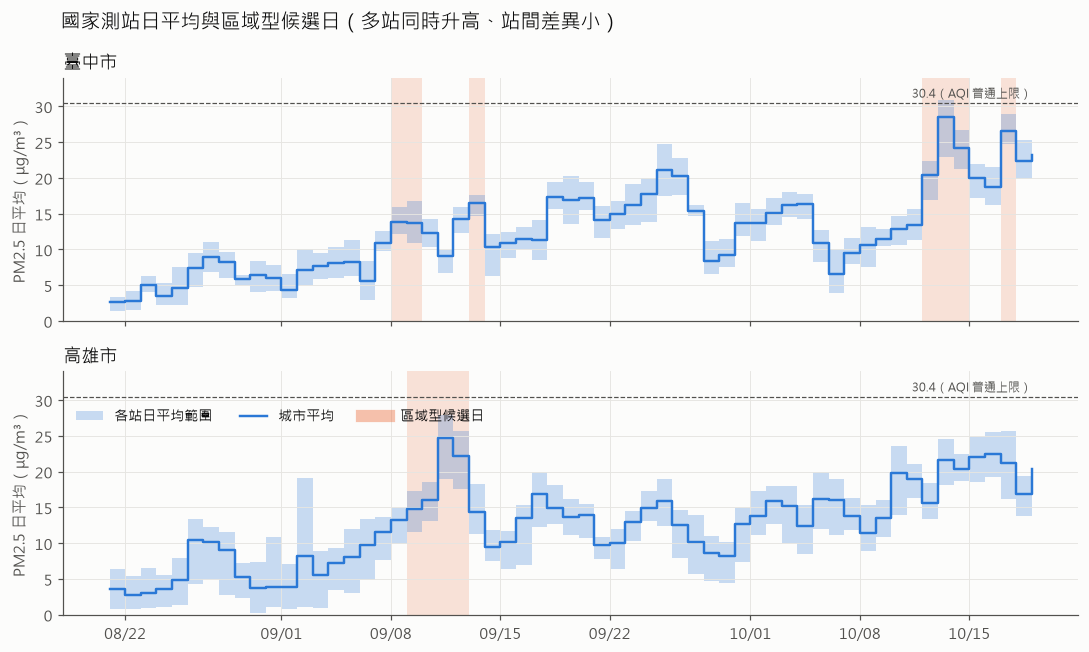

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, c in zip(axes, CITIES):
    d = D[c]
    for t in d.index[d["regional_candidate"]]:
        ax.axvspan(t, t + pd.Timedelta(days=1), color=ORANGE, alpha=0.18, lw=0)
    ax.fill_between(d.index, d["min"], d["max"], step="post", color=BLUE, alpha=0.25, lw=0, label="各站日平均範圍")
    ax.step(d.index, d["mean"], where="post", color=BLUE, lw=1.6, label="城市平均")
    ax.axhline(30.4, color=INK2, lw=0.8, ls="--"); ax.text(d.index[-1], 31.2, "30.4（AQI 普通上限）", fontsize=8, color=INK2, ha="right")
    ax.set_title(c, loc="left", fontsize=12); ax.set_ylabel("PM2.5 日平均（μg/m³）")
axes[1].plot([], [], color=ORANGE, alpha=0.4, lw=8, label="區域型候選日")
axes[1].legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.9), ncol=3, fontsize=9)
for ax in axes: ax.set_ylim(0, 34)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m/%d", tz=TZ))
fig.suptitle("國家測站日平均與區域型候選日（多站同時升高、站間差異小）", x=0.06, ha="left", fontsize=13)
fig.tight_layout(); fig.savefig(FIG / "t21_fig1_daily_candidates.png", dpi=160)

## 2. 區域型時段（小時尺度，連續 6 小時以上）

In [4]:
EP = {c: rg.regional_episodes(P[c]) for c in CITIES}
for c in CITIES:
    print(f"\n{c}"); print(EP[c].round(2).to_string())


臺中市
                      start                       end  hours  peak_median  mean_C
0 2026-09-08 17:00:00+08:00 2026-09-09 01:00:00+08:00      9         18.0    0.94
1 2026-09-12 09:00:00+08:00 2026-09-12 14:00:00+08:00      6         27.0    0.97
2 2026-10-12 17:00:00+08:00 2026-10-12 22:00:00+08:00      6         29.5    1.00
3 2026-10-13 00:00:00+08:00 2026-10-13 07:00:00+08:00      8         32.0    1.00
4 2026-10-13 17:00:00+08:00 2026-10-14 05:00:00+08:00     13         38.5    1.00

高雄市
                      start                       end  hours  peak_median  mean_C
0 2026-09-09 02:00:00+08:00 2026-09-09 08:00:00+08:00      7         19.5    0.90
1 2026-09-12 01:00:00+08:00 2026-09-12 10:00:00+08:00     10         34.0    0.98


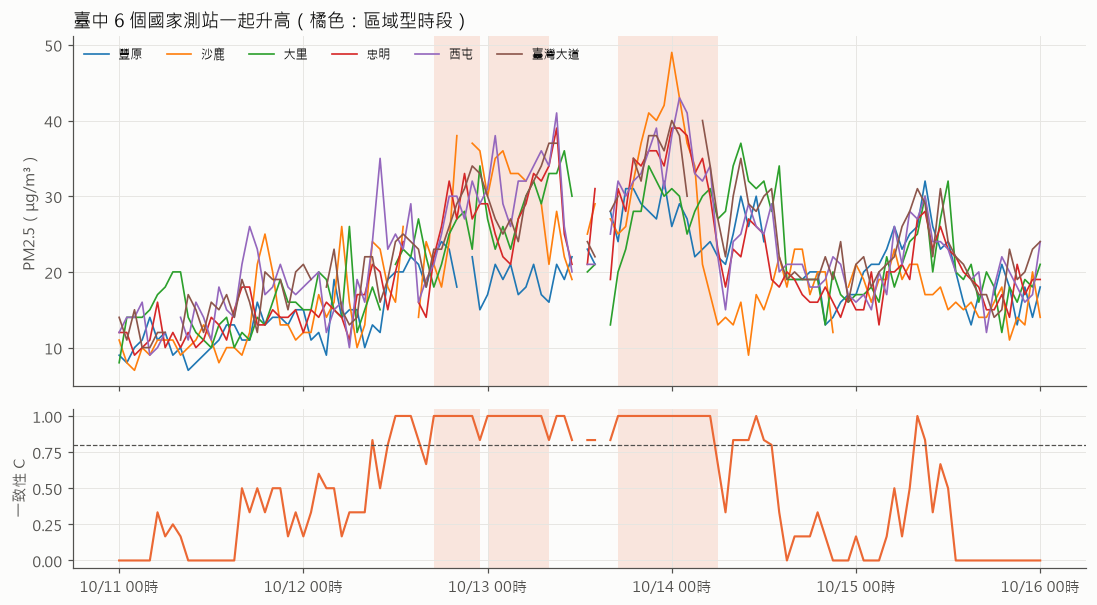

In [5]:
# 圖 2：臺中 10/12～10/15 的多站同時升高（最明顯的區域型時段）
c = "臺中市"; s, e = pd.Timestamp("2026-10-11", tz="Asia/Taipei"), pd.Timestamp("2026-10-16", tz="Asia/Taipei")
h, p = H[c].loc[s:e], P[c].loc[s:e]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for site in h.columns:
    ax1.plot(h.index, h[site], lw=1.1, label=names[c][site])
for _, r in EP[c].iterrows():
    if r["end"] >= s and r["start"] <= e:
        for ax in (ax1, ax2):
            ax.axvspan(r["start"], r["end"] + pd.Timedelta(hours=1), color=ORANGE, alpha=0.15, lw=0)
ax1.set_ylabel("PM2.5（μg/m³）"); ax1.legend(frameon=False, ncol=6, fontsize=8, loc="upper left")
ax1.set_title("臺中 6 個國家測站一起升高（橘色：區域型時段）", loc="left", fontsize=12)
ax2.plot(p.index, p["C"], color=ORANGE, lw=1.4); ax2.axhline(0.8, color=INK2, lw=0.8, ls="--")
ax2.set_ylim(-0.05, 1.05); ax2.set_ylabel("一致性 C")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%m/%d %H時", tz=TZ))
fig.tight_layout(); fig.savefig(FIG / "t21_fig2_taichung_regional.png", dpi=160)

## 3. 對照：局部型候選（單站升高、其他測站正常）

In [6]:
LOC = {c: rg.local_station_hours(H[c], P[c]) for c in CITIES}
for c in CITIES:
    l = LOC[c].assign(sitename=lambda x: x["siteid"].map(names[c]))
    print(f"\n{c}：{len(l)} 個局部型候選小時")
    print(l.groupby("sitename").size().sort_values(ascending=False).to_string())
    print(l.sort_values("excess", ascending=False).head(5).round(1).to_string())


臺中市：56 個局部型候選小時
sitename
臺灣大道    15
大里      14
沙鹿      12
西屯       8
豐原       7
                        time siteid  pm25  others_median  excess sitename
31 2026-10-04 21:00:00+08:00     30  50.0           15.0    35.0       大里
25 2026-09-20 21:00:00+08:00     30  37.0           16.0    21.0       大里
4  2026-10-17 17:00:00+08:00     28  38.0           18.0    20.0       豐原
8  2026-10-02 01:00:00+08:00     29  30.0           12.0    18.0       沙鹿
10 2026-10-04 07:00:00+08:00     29  30.0           12.0    18.0       沙鹿

高雄市：179 個局部型候選小時
sitename
小港    39
大寮    34
林園    28
美濃    18
鳳山    17
橋頭    15
楠梓    13
仁武     6
復興     5
前金     2
左營     2
                         time siteid  pm25  others_median  excess sitename
162 2026-09-27 19:00:00+08:00     58  55.0            7.0    48.0       小港
58  2026-09-12 20:00:00+08:00     51  35.0           11.0    24.0       大寮
118 2026-09-08 01:00:00+08:00     53  31.0            8.0    23.0       楠梓
86  2026-10-16 23:00:00+08:00     51  40.0       

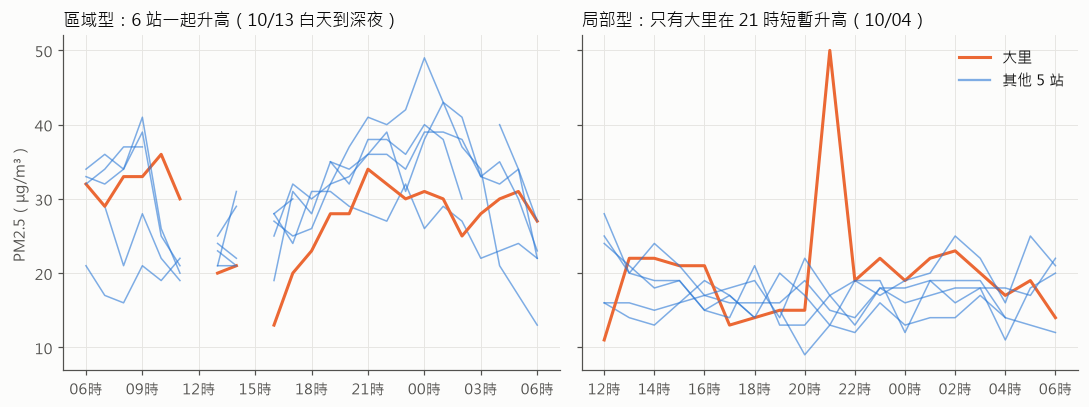

In [7]:
# 圖 3：對照兩種型態——區域型（臺中 10/13）vs 局部型（臺中大里 10/04 21 時，只持續 1 小時）
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
cases = [("臺中市", "2026-10-13 06:00", "2026-10-14 06:00", "區域型：6 站一起升高（10/13 白天到深夜）"),
         ("臺中市", "2026-10-04 12:00", "2026-10-05 06:00", "局部型：只有大里在 21 時短暫升高（10/04）")]
for ax, (c, s, e, title) in zip(axes, cases):
    h = H[c].loc[pd.Timestamp(s, tz="Asia/Taipei"):pd.Timestamp(e, tz="Asia/Taipei")]
    for site in h.columns:
        hl = names[c][site] == "大里"
        ax.plot(h.index, h[site], lw=2.0 if hl else 1.0, color=ORANGE if hl else BLUE, alpha=1 if hl else 0.6,
                label="大里" if hl else None)
    ax.set_title(title, loc="left", fontsize=11); ax.xaxis.set_major_formatter(mdates.DateFormatter("%H時", tz=TZ))
axes[0].set_ylabel("PM2.5（μg/m³）"); axes[1].legend(frameon=False, loc="upper right")
axes[1].plot([], [], color=BLUE, alpha=0.6, label="其他 5 站"); axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout(); fig.savefig(FIG / "t21_fig3_regional_vs_local.png", dpi=160)

## 4. 兩個城市同時升高的日子

In [8]:
both = D["臺中市"]["regional_candidate"] & D["高雄市"]["regional_candidate"].reindex(D["臺中市"].index, fill_value=False)
print("兩市同為候選日：", [f"{t:%m/%d}" for t in both.index[both]])
m = pd.DataFrame({c: D[c]["mean"] for c in CITIES}).dropna()
print("兩市日平均的相關係數：", round(m.corr().iloc[0, 1], 2))

兩市同為候選日： ['09/09']
兩市日平均的相關係數： 0.74


## 結論（初步）

- 國家測站確實有「多站同時升高、站間差異小」的日子與時段，可以作為區域型事件的候選，交給微型感測器資料驗證 Algorithm 2。
- 判斷「升高」只用相對門檻（+50%）時，8 月底的低濃度日（城市平均約 8 μg/m³）也會被選出，所以加上絕對門檻 +5 μg/m³。
- 基準用「前 14 天中位數」，所以**季節性的緩慢上升**（例如 10 月中旬高雄逐日上升）不會被當成事件；這是刻意的設計，但也代表持續數週的高污染期需要另外的指標。
- **成因無法從測站資料判斷**：兩市同時升高可能與天氣型態或境外傳輸有關，需要對照環境部空品預報、境外污染預警等外部紀錄（待查證）。